# 05 — Interpretação dos Modelos (XAI) e Simulação *Buy-Low / Sell-High*

**Objetivo.** O notebook tem quatro partes:
1. Abrir a "caixa-preta" do modelo final com valores SHAP (Lundberg e Lee, 2017).
2. Identificar quais variáveis, em especial as tático-técnicas, determinam a valorização futura, e
   como isso muda entre as 12 categorias.
3. Traduzir as previsões em decisões de recrutamento.
4. Quantificar o retorno e o risco financeiro de uma estratégia *buy-low / sell-high* em
   *backtest* fora da amostra.

**Entradas:**
- modelos finais do notebook 04 (`models/04_model_training/final/manifest.json`): o *ensemble*
  global de CatBoost, XGBoost e Ridge, os quantis e a camada de magnitude;
- `data/processed/train_test_lags.parquet`;
- `data/processed/predictions_best.parquet`: previsões fora da amostra da janela expandida.

**Saídas:** figuras em `reports/figures/05_model_interpretation/`, tabelas em
`reports/tables/05_model_interpretation/` e os valores SHAP em `data/processed/shap_values_T{k}.parquet`.

**Leitura dos valores SHAP.** O modelo prevê o log-retorno $y=\ln(V_{T+k}/V_T)$, e o SHAP decompõe
cada previsão em contribuições aditivas: $\hat y_i = \phi_0 + \sum_j \phi_{ij}$. Uma contribuição
$\phi_{ij}$ em log-retorno equivale, aproximadamente, a $100\,\phi_{ij}$% de variação no valor
(+0,10 ≈ +10,5%). No *ensemble*, os SHAP são a média dos SHAP dos três componentes, o que
preserva a aditividade:
- **CatBoost e XGBoost:** `shap.TreeExplainer`;
- **Ridge:** forma fechada, $\phi_j = w_j(x'_j-\bar x'_j)$.

**SHAP global, leitura por categoria.** Os SHAP vêm do modelo global ajustado em todas as
temporadas. O notebook 04 mostrou que esse modelo supera os 12 modelos segmentados. A leitura "por
categoria" agrega as explicações do modelo global dentro de cada categoria C1–C12. Assim, as
diferenças entre categorias refletem interações aprendidas pelo modelo, e não 12 modelos ajustados
com amostras pequenas.

## 0. Configuração

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display

from football_analytics import feature_catalog as fc
from football_analytics import interpretation as it
from football_analytics import plotting as pl
from football_analytics import sample as sp
from football_analytics.config import default_config
from football_analytics.io import load_table, save_table
from football_analytics.logging_utils import setup_logging

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

cfg = default_config()
paths = cfg.paths
logger = setup_logging(paths.logs / "05_model_interpretation.log")
pl.setup_style()
FIG = pl.FigureRegistry(paths.figures("05_model_interpretation"),
                        source="Elaboração própria com dados de FBref, Understat, Sofascore e Transfermarkt (2026)")
TABLES = paths.tables("05_model_interpretation")
TABLES.mkdir(parents=True, exist_ok=True)


def save_csv(df: pd.DataFrame, name: str, index: bool = True) -> None:
    df.to_csv(TABLES / f"{name}.csv", index=index, encoding="utf-8-sig", float_format="%.5f")


HORIZONS = (1, 2)
CATEGORIES = [f"C{i}" for i in range(1, 13)]
CAT_LABELS = sp.category_labels()
BANDS = list(sp.AGE_BAND_LABELS)
POS = list(sp.POSITIONS)
CATEGORICAL = ["league", "age_band", "position_group"]
CAT_VAR_LABELS = {"league": "Liga", "age_band": "Faixa etária", "position_group": "Posição"}
CAT_VAR_GROUP = {"league": "Contexto", "age_band": "Demográfico", "position_group": "Demográfico"}


def label(c: str) -> str:
    return CAT_VAR_LABELS.get(c) or fc.label(c)


def group(c: str) -> str:
    return CAT_VAR_GROUP.get(c) or fc.CATALOG[c].group


GROUP_ORDER = ["Demográfico", "Contratual", "Mercado", "Contexto", "Dinâmica de mercado", "Valor justo", "Defasagem",
               "Volume", "Ofensivo", "Criação e posse", "Defensivo", "Disciplina", "Avaliação agregada"]
PERFORMANCE_GROUPS = ["Volume", "Ofensivo", "Criação e posse", "Defensivo", "Disciplina", "Avaliação agregada"]

/home/alvaro/Documents/TCC/football-analytics/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
panel = load_table(paths.processed / "train_test_lags.parquet")
best = load_table(paths.processed / "predictions_best.parquet")
finals = {k: it.load_final(paths.root, k) for k in HORIZONS}
for k, f in finals.items():
    print(f"T+{k}: ensemble {list(f.components)} | {len(f.feature_names)} variáveis pré-processadas | "
          f"treino {f.manifest['global']['cat']['n_train']:,} obs.")

T+1: ensemble ['cat', 'xgb', 'ridge'] | 114 variáveis pré-processadas | treino 9,617 obs.
T+2: ensemble ['cat', 'xgb', 'ridge'] | 114 variáveis pré-processadas | treino 9,357 obs.


## 1. Valores SHAP do *ensemble*

Os SHAP são calculados para todas as observações do painel com alvo observado. As *dummies* de
liga, faixa etária e posição são somadas de volta em uma única variável cada. A aditividade
($\phi_0 + \sum_j\phi_{ij} = \hat y_i$) é verificada numericamente.

In [3]:
shap_vals, bases, frames = {}, {}, {}
for k in HORIZONS:
    d = panel[panel[f"has_target_T{k}"] == 1]
    phi, base = it.ensemble_shap(finals[k], d)
    phi = it.collapse_dummies(phi, CATEGORICAL)
    shap_vals[k], bases[k], frames[k] = phi, base, d
    save_table(phi.assign(season=d["season"].to_numpy(), fbref_player_id=d["fbref_player_id"].to_numpy()).reset_index(drop=True),
               paths.processed / f"shap_values_T{k}.parquet", source=f"notebook 05: SHAP do ensemble global, T+{k}")
    print(f"T+{k}: {phi.shape[0]:,} obs. × {phi.shape[1]} variáveis | φ0 = {base:.3f} "
          f"(≈ {np.expm1(base) * 100:.1f}% de variação mediana)")

imp = pd.concat({f"T+{k}": it.importance(shap_vals[k])["mean_abs_shap"] for k in HORIZONS}, axis=1)
imp["grupo"] = [group(c) for c in imp.index]
imp["variavel"] = [label(c) for c in imp.index]
imp["rank_T+1"] = imp["T+1"].rank(ascending=False).astype(int)
imp = imp.sort_values("T+1", ascending=False)
save_csv(imp, "tab01_importancia_shap_global")
imp.head(25)

I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/shap_values_T1.parquet rows=9617 cols=110


T+1: 9,617 obs. × 108 variáveis | φ0 = -0.159 (≈ -14.7% de variação mediana)


I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/shap_values_T2.parquet rows=9357 cols=110


T+2: 9,357 obs. × 108 variáveis | φ0 = -0.381 (≈ -31.7% de variação mediana)


,T+1,T+2,grupo,variavel,rank_T+1
age,0.125,0.225,Demográfico,Idade,1
log_value_T,0.073,0.070,Mercado,log V_T,2
age_sq,0.066,0.150,Demográfico,Idade²,3
value_gap_T,0.043,0.089,Valor justo,Gap de avaliação,4
mkt_log_return_6m,0.028,0.030,Dinâmica de mercado,Variação do valor em 6 meses,5
team_points_per_game,0.025,0.023,Contexto,Pontos/jogo da equipe,6
value_share_of_club,0.020,0.031,Mercado,% do valor do elenco,7
delta_minutes_share_pct,0.019,0.024,Defasagem,Δ % dos minutos (T−1→T),8
age_band,0.019,0.032,Demográfico,Faixa etária,9
league,0.019,0.023,Contexto,Liga,10


## 2. Importância global das variáveis

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig01_shap_beeswarm_T1.png


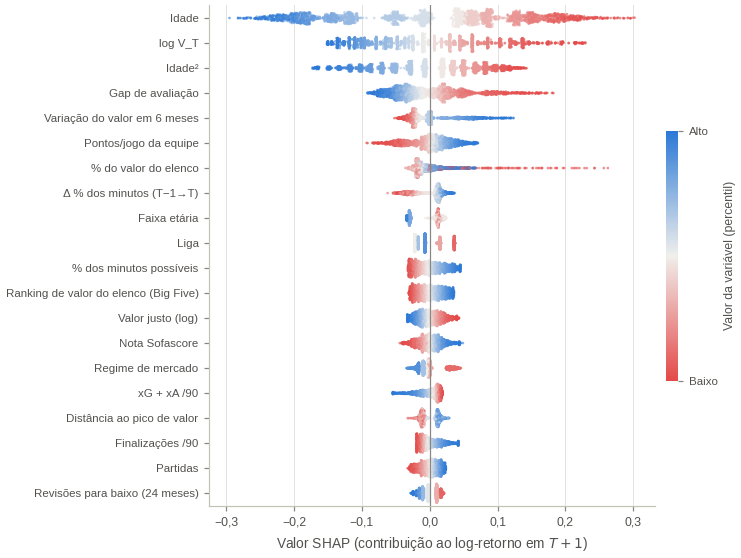

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig02_shap_beeswarm_T2.png


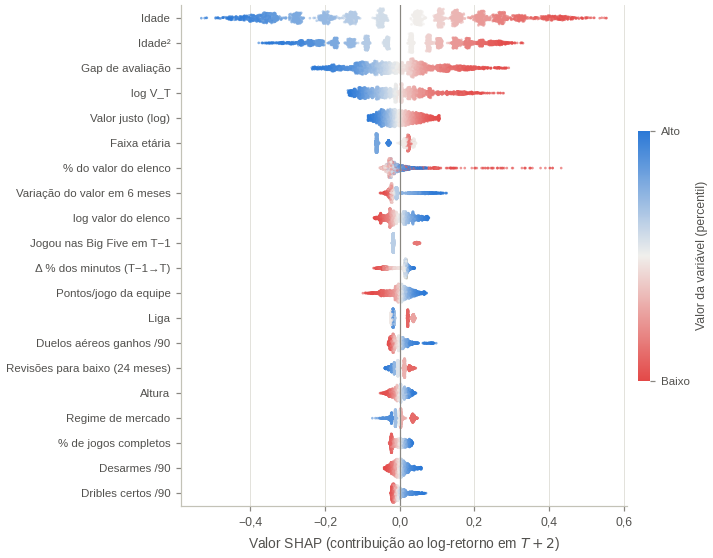

In [4]:
def display_matrix(k: int) -> pd.DataFrame:
    d = frames[k]
    X = pd.DataFrame(index=d.index)
    for c in shap_vals[k].columns:
        X[c] = d[c].astype("category").cat.codes.astype(float) if c in CATEGORICAL else d[c].astype(float)
    return X


for k, name in ((1, "fig01_shap_beeswarm_T1"), (2, "fig02_shap_beeswarm_T2")):
    phi = shap_vals[k]
    top = phi.abs().mean().sort_values(ascending=False).head(20).index.tolist()
    fig, ax = plt.subplots(figsize=pl.figsize(15))
    mappable = pl.beeswarm(ax, phi, display_matrix(k), top, [label(c) for c in top])
    ax.set_xlabel(f"Valor SHAP (contribuição ao log-retorno em $T+{k}$)")
    ax.xaxis.set_major_formatter(pl.br_formatter(1))
    ax.tick_params(axis="y", labelsize=7.5)
    cbar = fig.colorbar(mappable, ax=ax, shrink=0.5, pad=0.02, ticks=[0, 1])
    cbar.ax.set_yticklabels(["Baixo", "Alto"], fontsize=7.5)
    cbar.set_label("Valor da variável (percentil)", fontsize=8)
    cbar.outline.set_visible(False)
    FIG.save(fig, name, f"Valores SHAP das 20 variáveis mais importantes para o log-retorno em T+{k} (ensemble global)",
             note="Cada ponto é um atleta–temporada (amostra de 2.500). Cor: percentil do valor da variável (azul = alto). "
                  "À direita de zero, a variável eleva a valorização prevista.")
    plt.show()

**Leitura.** Quatro blocos explicam a maior parte da valorização prevista (participação no
$|\phi|$ total em $T+1$ / $T+2$):

| Bloco | Participação ($T+1$ / $T+2$) | Variáveis |
|---|---|---|
| **Idade** (demografia) | 27% / 35% | idade, idade², faixa etária |
| **Nível de preço** (mercado) | 14% / 11% | $\log V_T$, % do valor do elenco, *ranking* do elenco |
| **Trajetória do valor** | 20% / 24% | gap de avaliação, valor justo, variação em 6 meses, revisões, *momentum* |
| **Desempenho tático-técnico** | 32% / 24% | volume, ofensivo, criação, defensivo, disciplina, nota |

A idade é a variável isolada mais importante, com efeito monotônico: cada ano a mais reduz a
valorização prevista. O $\log V_T$ tem efeito **negativo**: atletas mais caros se valorizam menos,
em termos relativos. Esse é o sinal de **reversão de nível** compatível com a premissa *buy-low*.
O **gap de avaliação** é a quarta variável em $T+1$ e a terceira em $T+2$: atletas subavaliados
(gap negativo, em vermelho) recebem contribuição positiva. Entre as variáveis de dinâmica, a
**variação do valor nos últimos seis meses** é a mais forte, porque reavaliações recentes para cima
tendem a continuar (ancoragem e ajuste). Os pontos por jogo da equipe e a participação nos minutos
completam o quadro: atuar muito num time vencedor eleva a valorização seguinte.

## 3. Como os determinantes mudam ao longo da carreira (12 categorias)

A figura mostra, para cada categoria, a participação de cada grupo de variáveis no total de
$|\phi|$. Ela testa empiricamente a premissa da especificação (§6.4, Khalife et al., 2025): a
importância do potencial e da trajetória deveria cair com a idade, e a do desempenho operacional,
subir.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig03_grupos_por_categoria.png


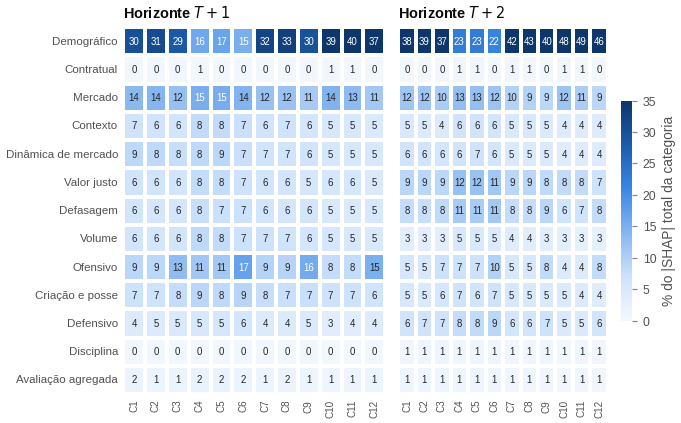

In [5]:
cat_share = {}
for k in HORIZONS:
    phi, d = shap_vals[k], frames[k]
    by_group = phi.abs().T.groupby([group(c) for c in phi.columns]).sum().T
    share = by_group.groupby(d["category"].to_numpy()).mean()
    share = share.div(share.sum(axis=1), axis=0).mul(100).reindex(index=CATEGORIES, columns=GROUP_ORDER).fillna(0)
    cat_share[k] = share
save_csv(pd.concat(cat_share, names=["horizonte"]), "tab02_participacao_grupos_por_categoria")

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(11), sharey=True, gridspec_kw={"wspace": 0.05})
for ax, k in zip(axes, HORIZONS):
    d = cat_share[k].T
    d.columns = list(d.columns)
    sns.heatmap(d, annot=pl.annotations(d, 0), fmt="", cmap=pl.SEQUENTIAL, vmin=0, vmax=35, linewidths=1.5,
                linecolor=pl.SURFACE, cbar=ax is axes[1], ax=ax, annot_kws={"fontsize": 6.3},
                cbar_kws={"label": "% do |SHAP| total da categoria", "shrink": 0.6})
    ax.set_title(f"Horizonte $T+{k}$")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(length=0, labelsize=6.5)
    ax.tick_params(axis="y", labelsize=7.5)
    ax.grid(False)
FIG.save(fig, "fig03_grupos_por_categoria",
         "Participação de cada grupo de variáveis na explicação SHAP da valorização, por categoria",
         note="Média de |SHAP| somada por grupo, como % do total de cada categoria (C1–C3: 16–23 anos; C4–C6: 24–28; "
              "C7–C9: 29–32; C10–C12: 33+; em cada trinca, DEF, MEI e ATA). Defasagem inclui o momentum do valor.")
plt.show()

In [6]:
# Equivalente empírico da coluna "SHAP Top 3" da Tabela 6.1 da especificação.
rows = []
for k in HORIZONS:
    phi, d = shap_vals[k], frames[k]
    for c in CATEGORIES:
        mask = (d["category"] == c).to_numpy()
        imp_c = phi[mask].abs().mean().drop(labels=[x for x in CATEGORICAL if x in phi.columns]).sort_values(ascending=False)
        top = imp_c.head(3)
        # direção: correlação de postos entre o valor da variável e sua contribuição
        sign = [np.sign(pd.Series(d.loc[mask, f].to_numpy()).corr(pd.Series(phi.loc[mask, f].to_numpy()), method="spearman"))
                for f in top.index]
        rows.append({"horizonte": f"T+{k}", "categoria": CAT_LABELS[c],
                     **{f"top{i + 1}": f"{label(f)} ({'+' if s > 0 else '−'})" for i, (f, s) in enumerate(zip(top.index, sign))},
                     "top_desempenho": next(label(f) for f in imp_c.index if group(f) in PERFORMANCE_GROUPS)})
top3 = pd.DataFrame(rows)
save_csv(top3, "tab03_top3_shap_por_categoria", index=False)
top3

,horizonte,categoria,top1,top2,top3,top_desempenho
0,T+1,C1 · DEF 16–23,Idade (−),Idade² (−),log V_T (−),% dos minutos possíveis
1,T+1,C2 · MEI 16–23,Idade (−),Idade² (−),log V_T (−),% dos minutos possíveis
2,T+1,C3 · ATA 16–23,Idade (−),Idade² (−),log V_T (−),% dos minutos possíveis
3,T+1,C4 · DEF 24–28,log V_T (−),Idade (−),Gap de avaliação (−),% dos minutos possíveis
4,T+1,C5 · MEI 24–28,log V_T (−),Idade (−),Gap de avaliação (−),% dos minutos possíveis
5,T+1,C6 · ATA 24–28,log V_T (−),Idade (−),Gap de avaliação (−),% dos minutos possíveis
6,T+1,C7 · DEF 29–32,Idade (−),Idade² (−),log V_T (−),% dos minutos possíveis
7,T+1,C8 · MEI 29–32,Idade (−),Idade² (−),log V_T (−),% dos minutos possíveis
8,T+1,C9 · ATA 29–32,Idade (−),Idade² (−),log V_T (−),xG + xA /90
9,T+1,C10 · DEF 33+,Idade (−),Idade² (−),log V_T (−),% dos minutos possíveis


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig04_top5_por_categoria.png


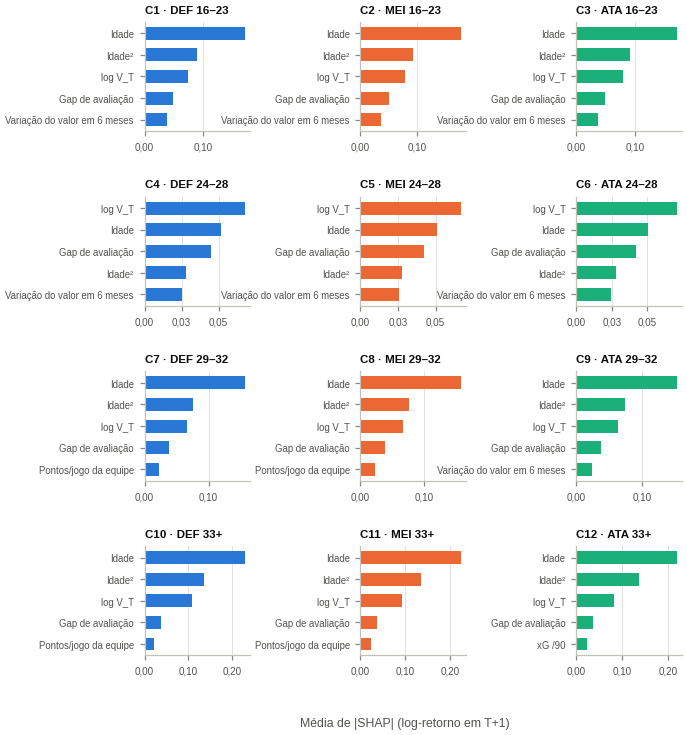

In [7]:
k = 1
phi, d = shap_vals[k], frames[k]
numeric_cols = [c for c in phi.columns if c not in CATEGORICAL]
fig, axes = plt.subplots(4, 3, figsize=pl.figsize(19), gridspec_kw={"hspace": 0.6, "wspace": 1.05})
for ax, c in zip(axes.ravel(), CATEGORIES):
    mask = (d["category"] == c).to_numpy()
    top = phi.loc[mask, numeric_cols].abs().mean().sort_values(ascending=False).head(5)[::-1]
    colors = [pl.POSITION_COLORS[c_pos] for c_pos in [sp.POSITIONS[(int(c[1:]) - 1) % 3]] * len(top)]
    ax.barh(range(len(top)), top.to_numpy(), color=colors, height=0.6)
    ax.set_yticks(range(len(top)), [label(f) for f in top.index], fontsize=6.3)
    ax.set_title(CAT_LABELS[c], fontsize=7.5)
    ax.xaxis.set_major_formatter(pl.br_formatter(2))
    ax.tick_params(axis="x", labelsize=6.5)
    ax.grid(axis="y", visible=False)
fig.supxlabel("Média de |SHAP| (log-retorno em T+1)", fontsize=8, color=pl.INK_SECONDARY, y=0.02)
FIG.save(fig, "fig04_top5_por_categoria",
         "As cinco variáveis com maior contribuição média (|SHAP|) para a valorização em T+1, por categoria",
         note="Linhas: faixas etárias (16–23, 24–28, 29–32, 33+). Colunas: defensores, meio-campistas e atacantes.")
plt.show()

**Leitura: o que muda ao longo da carreira.** A Figura 3 permite testar empiricamente a premissa da
especificação (§6.4).

- **Peso da idade.** É alto em todas as faixas, exceto no auge: 29–31% aos 16–23 anos, **15–17%
  aos 24–28**, 30–33% aos 29–32 e **37–40% aos 33+**. Nos veteranos, a depreciação biológica é
  o fator dominante.
- **Desempenho tático-técnico.** O peso é **máximo no auge** (35–41% em C4–C6) e menor nos
  veteranos (25–32%). A **trajetória do valor** (gap, dinâmica e *momentum*) segue o mesmo padrão
  (22–24% em C4–C6 contra 15–16% em C10–C12).
- **Posição.** Em todas as faixas, os **atacantes** dependem muito mais das métricas ofensivas
  (13–17% do total, contra 8–11% de defensores e meio-campistas).
- **Horizonte $T+2$.** Os pesos se deslocam para idade, gap de avaliação e trajetória, e o
  desempenho de uma única temporada perde importância (17–32%).

*Confronto com a especificação.* A especificação, apoiada em Khalife et al. (2025), previa que a
valoração dos veteranos fosse governada pela produção operacional. Os dados indicam o contrário:
para os atletas de 33 anos ou mais, a idade explica sozinha cerca de 40% da variação prevista, e o
desempenho, uma fração **menor** que no auge. A interpretação para o texto é que o mercado premia o
desempenho sobretudo enquanto ele sinaliza trajetória futura (24–28 anos). Nos veteranos, nem um
bom rendimento compensa a depreciação esperada.

A tabela de "top 3" (equivalente empírico da Tabela 6.1 da especificação) confirma o padrão: idade,
idade² e $\log V_T$ lideram todas as categorias, com o gap de avaliação em 3º lugar nos atletas de
24–28 anos.

## 4. Variáveis tático-técnicas mais determinantes, por posição

Atende ao objetivo da especificação de identificar as métricas de desempenho de maior peso na
valorização futura. Ficam de fora a idade, o mercado, a dinâmica de reavaliações e o valor justo.
A direção (+/−) é o sinal da correlação de postos entre o valor da métrica e sua contribuição
SHAP: (+) significa que mais da métrica eleva a valorização prevista.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig05_desempenho_por_posicao.png


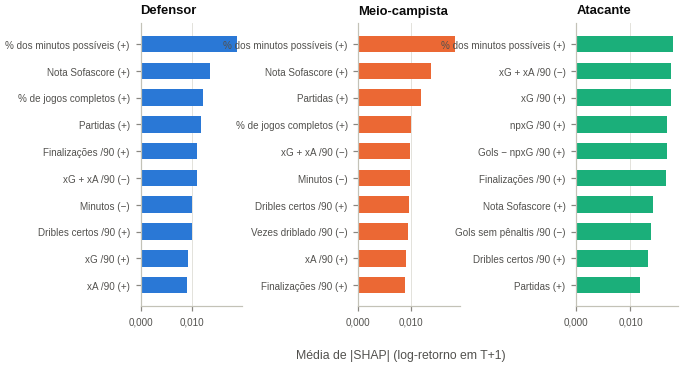

Participação do desempenho tático-técnico no |SHAP| total: T+1: 32.4%, T+2: 24.3%


In [8]:
perf_rows = []
fig, axes = plt.subplots(1, 3, figsize=pl.figsize(8.5), gridspec_kw={"wspace": 1.15})
for ax, pos in zip(axes, POS):
    k = 1
    phi, d = shap_vals[k], frames[k]
    mask = (d["position_group"] == pos).to_numpy()
    cols = [c for c in phi.columns if c not in CATEGORICAL and group(c) in PERFORMANCE_GROUPS]
    top = phi.loc[mask, cols].abs().mean().sort_values(ascending=False).head(10)
    signs = [np.sign(pd.Series(d.loc[mask, f].to_numpy()).corr(pd.Series(phi.loc[mask, f].to_numpy()), method="spearman"))
             for f in top.index]
    for f, v, s in zip(top.index, top.to_numpy(), signs):
        perf_rows.append({"posicao": sp.POSITION_LABELS[pos], "variavel": label(f), "grupo": group(f),
                          "mean_abs_shap_T1": v, "direcao": "+" if s > 0 else "−"})
    top, signs = top[::-1], signs[::-1]
    ax.barh(range(len(top)), top.to_numpy(), color=pl.POSITION_COLORS[pos], height=0.62)
    ax.set_yticks(range(len(top)), [f"{label(f)} ({'+' if s > 0 else '−'})" for f, s in zip(top.index, signs)], fontsize=6.5)
    ax.set_title(sp.POSITION_LABELS[pos], fontsize=8.5)
    ax.xaxis.set_major_formatter(pl.br_formatter(3))
    ax.tick_params(axis="x", labelsize=6.5)
    ax.grid(axis="y", visible=False)
fig.supxlabel("Média de |SHAP| (log-retorno em T+1)", fontsize=8, color=pl.INK_SECONDARY, y=-0.04)
perf_tab = pd.DataFrame(perf_rows)
save_csv(perf_tab, "tab04_top_desempenho_por_posicao", index=False)
FIG.save(fig, "fig05_desempenho_por_posicao",
         "As dez métricas tático-técnicas com maior contribuição para a valorização em T+1, por posição",
         note="(+): valores altos da métrica elevam a valorização prevista; (−): reduzem.")
plt.show()
share_perf = {k: shap_vals[k].abs().T.groupby([group(c) for c in shap_vals[k].columns]).sum().T.sum()
              .pipe(lambda s: s[PERFORMANCE_GROUPS].sum() / s.sum() * 100) for k in HORIZONS}
print("Participação do desempenho tático-técnico no |SHAP| total: "
      + ", ".join(f"T+{k}: {v:.1f}%" for k, v in share_perf.items()))

**Leitura: as variáveis tático-técnicas mais determinantes.** Dentro do vetor de desempenho, que
responde por 32% da explicação em $T+1$, duas famílias se destacam:

1. **Participação e regularidade**, nas três posições: % dos minutos possíveis, partidas, % de jogos
   completos e nota média do Sofascore, todos com efeito positivo. O mercado valoriza quem se
   firma como titular.
2. **Produção específica da posição:**
   - **atacantes:** xG/90, npxG/90, finalização acima do esperado (gols − npxG) e finalizações/90;
   - **meio-campistas:** dribles certos, xA e finalizações;
   - **defensores:** finalizações e dribles também aparecem, sinal de que o mercado premia
     defensores com participação ofensiva.

Os efeitos negativos de xG + xA/90 e de minutos absolutos, *condicionais* aos demais, refletem
colinearidade com xG/90 e com a participação nos minutos (o efeito líquido é dividido entre
variáveis correlacionadas). Eles não devem ser lidos isoladamente.

*Limitação.* As métricas que a especificação tratava como centrais (passes progressivos,
conduções progressivas, SCA, duelos aéreos) foram aproximadas por *proxies* do Sofascore e do
Understat, porque o FBref deixou de publicar os dados Opta. As *proxies* de criação têm peso
moderado.

## 5. Gráficos de dependência

Os gráficos de dependência mostram como a contribuição de uma variável varia com o seu valor. Isso
revela não linearidades e, pela cor, interações com a faixa etária.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig06_dependencia_shap.png


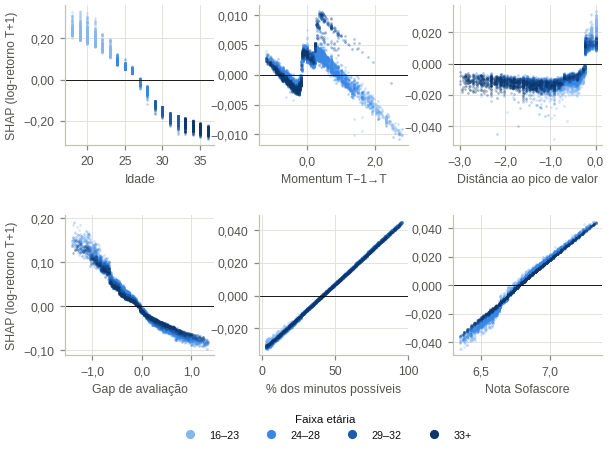

In [9]:
k = 1
phi, d = shap_vals[k], frames[k]
dep_vars = ["age", "log_return_lag1", "mkt_peak_gap", "value_gap_T", "minutes_share_pct", "sofascore_rating"]
fig, axes = plt.subplots(2, 3, figsize=pl.figsize(10.5), gridspec_kw={"hspace": 0.5, "wspace": 0.3})
band_colors = dict(zip(BANDS, pl.AGE_BAND_COLORS))
for ax, f in zip(axes.ravel(), dep_vars):
    x = d[f].astype(float)
    lo, hi = x.quantile([0.01, 0.99])
    for band in BANDS:
        m = (d["age_band"] == band).to_numpy() & x.between(lo, hi).to_numpy()
        ax.scatter(x[m], phi.loc[m, f], s=3, alpha=0.35, color=band_colors[band], linewidths=0, label=band)
    ax.axhline(0, color=pl.INK, linewidth=0.6)
    ax.set_xlabel(label(f), fontsize=8)
    span = phi[f].abs().quantile(0.99)
    ax.yaxis.set_major_formatter(pl.br_formatter(3 if span < 0.05 else 2))
    ax.xaxis.set_major_formatter(pl.br_formatter(1 if f in ("log_return_lag1", "mkt_peak_gap", "value_gap_T", "sofascore_rating") else 0))
for ax in axes[:, 0]:
    ax.set_ylabel("SHAP (log-retorno T+1)", fontsize=8)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, markersize=5) for c in pl.AGE_BAND_COLORS]
fig.legend(handles, BANDS, title="Faixa etária", loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=7, title_fontsize=7.5)
FIG.save(fig, "fig06_dependencia_shap",
         "Gráficos de dependência SHAP das principais variáveis para a valorização em T+1",
         note="Cada ponto é um atleta–temporada; extremos (1% de cada lado) omitidos.")
plt.show()

**Leitura.** Os gráficos de dependência mostram cinco relações:
- **Idade:** efeito praticamente linear e decrescente, de +0,25 aos 18 anos a −0,25 aos 35, com
  cruzamento do zero por volta dos 27 anos.
- **Gap de avaliação:** efeito monotônico e **convexo para baixo**. Os mais subavaliados
  (gap < −1) recebem até +0,15 a +0,20 (≈ +16% a +22%), e os sobreavaliados, no máximo −0,10. A
  correção de preço é mais forte para quem está barato do que para quem está caro.
- **% dos minutos possíveis e nota Sofascore:** relações lineares e positivas. Jogar 90% dos minutos
  possíveis contribui com cerca de +0,04, e jogar 10%, com cerca de −0,03: uma diferença de ≈ 7 p.p.
  de valorização.
- ***Momentum* anual (T−1→T):** contribuição pequena e não monotônica. Altas passadas muito grandes
  (log-retorno > 1) passam a ter efeito negativo, sinal de **reversão após saltos extremos**. A
  variação de seis meses, mais recente, carrega a maior parte do sinal de continuidade.
- **Distância ao pico:** atletas no próprio pico (gap ≈ 0) recebem efeito positivo. Os que estão
  muito abaixo do pico recebem efeito negativo, o que indica que o mercado não espera recuperação de
  quem já entrou em declínio.

## 6. Explicações individuais (*waterfall*)

Para cada faixa etária, o gráfico decompõe a previsão do atleta com maior valorização esperada
pelo modelo em 30/06/2024 (teste final, previsão fora da amostra). A decomposição usa o modelo
final. O título traz o valor em $T$, o $\Delta V\%$ previsto (mediano e esperado), o intervalo de
80% e o $\Delta V\%$ realizado até 30/06/2025.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig07_waterfall_exemplos.png


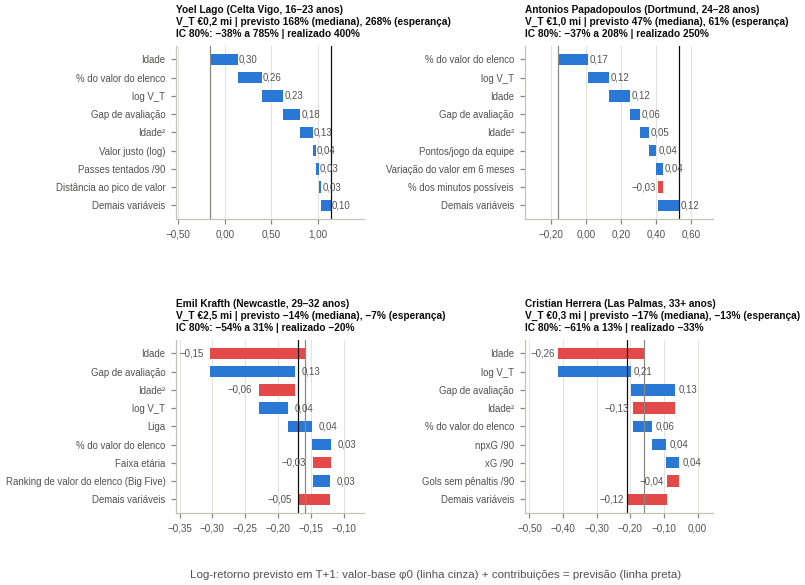

,fb_player,fb_team,age_band,value_T,dv_pct_pred_median,dv_pct_pred_mean,dv_pct_true
0,Yoel Lago,Celta Vigo,16–23,"200,000.000",168.193,268.330,400.000
1,Antonios Papadopoulos,Dortmund,24–28,"1,000,000.000",46.946,61.348,250.000
2,Emil Krafth,Newcastle,29–32,"2,500,000.000",-13.600,-6.545,-20.000
3,Cristian Herrera,Las Palmas,33+,"300,000.000",-17.338,-12.740,-33.333


In [10]:
k = 1
hold = best[(best["horizon"] == k) & best["is_holdout"]].copy()
hold = hold.merge(panel[["season", "fbref_player_id", "age"]], on=["season", "fbref_player_id"], how="left")
picks = hold.sort_values("dv_pct_pred_mean", ascending=False).groupby("age_band_x" if "age_band_x" in hold else "age_band").head(1)
band_col = "age_band_x" if "age_band_x" in hold else "age_band"
picks = picks.set_index(band_col).reindex(BANDS).reset_index()
phi_full, d_full = shap_vals[k], frames[k]
key_index = pd.Series(range(len(d_full)), index=pd.MultiIndex.from_frame(d_full[["season", "fbref_player_id"]]))

fig, axes = plt.subplots(2, 2, figsize=pl.figsize(14), gridspec_kw={"hspace": 0.7, "wspace": 0.85})
wf_rows = []
for ax, (_, r) in zip(axes.ravel(), picks.iterrows()):
    i = key_index[(r["season"], r["fbref_player_id"])]
    contrib = phi_full.iloc[i]
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8)
    rest = contrib.drop(top.index).sum()
    items = list(top.items()) + [("Demais variáveis", rest)]
    start = bases[k]
    path = np.cumsum([bases[k]] + [v for _, v in items])
    lo, hi = path.min(), path.max()
    pad = (hi - lo) * 0.28
    for j, (name, v) in enumerate(items):
        ax.barh(j, v, left=start, color=pl.BLUE if v >= 0 else pl.RED, height=0.62)
        ax.text(start + v + (0.01 if v >= 0 else -0.01), j, pl.br(v, 2), va="center", ha="left" if v >= 0 else "right",
                fontsize=6.3, color=pl.INK_SECONDARY)
        start += v
        wf_rows.append({"atleta": r["fb_player"], "variavel": name if name == "Demais variáveis" else label(name), "shap": v})
    ax.axvline(bases[k], color=pl.INK_MUTED, linewidth=0.8)
    ax.axvline(start, color=pl.INK, linewidth=0.8)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_yticks(range(len(items)), [n if n == "Demais variáveis" else label(n) for n, _ in items], fontsize=6.3)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(pl.br_formatter(2))
    ax.tick_params(axis="x", labelsize=6.5)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{r['fb_player']} ({r['fb_team']}, {r[band_col]} anos)\n"
                 f"V_T €{pl.br(r['value_T'] / 1e6, 1)} mi | previsto {pl.br_pct(r['dv_pct_pred_median'], 0)} (mediana), "
                 f"{pl.br_pct(r['dv_pct_pred_mean'], 0)} (esperança)\n"
                 f"IC 80%: {pl.br_pct(np.expm1(r['q10_conf']) * 100, 0)} a {pl.br_pct(np.expm1(r['q90_conf']) * 100, 0)} | "
                 f"realizado {pl.br_pct(r['dv_pct_true'], 0)}", fontsize=6.6, loc="left")
fig.supxlabel("Log-retorno previsto em T+1: valor-base φ0 (linha cinza) + contribuições = previsão (linha preta)",
              fontsize=7.5, color=pl.INK_SECONDARY, y=0.0)
save_csv(pd.DataFrame(wf_rows), "tab05_waterfall_exemplos", index=False)
FIG.save(fig, "fig07_waterfall_exemplos",
         "Decomposição SHAP da previsão de valorização em T+1 para o atleta de maior valorização esperada em cada faixa etária (2023/24)",
         note="Previsões fora da amostra do teste final; contribuições do modelo final. Valores em log-retorno.")
plt.show()
picks[["fb_player", "fb_team", band_col, "value_T", "dv_pct_pred_median", "dv_pct_pred_mean", "dv_pct_true"]]

**Leitura.** Os quatro casos ilustram como a mesma estrutura gera previsões opostas.

- **Yoel Lago** (Celta, 16–23 anos, € 0,2 mi): previsão de +168% (mediana) e +268% (esperança).
  Ela vem da idade (+0,30), da participação mínima no valor do elenco e do $V_T$ baixo, que indicam
  espaço de revisão, e de um gap de avaliação favorável (+0,18). Ele se valorizou 400%, dentro do
  intervalo de 80% (−38% a +785%).
- **Antonios Papadopoulos** (Dortmund, 24–28 anos, € 1 mi): previsão de +47% a +61%, com realização
  de +250%. O sentido estava certo, mas a magnitude ficou abaixo do realizado.
- **Emil Krafth** (29–32 anos) e **Cristian Herrera** (33+): os melhores casos dessas faixas ainda têm
  previsão negativa. O efeito da idade (−0,15 e −0,26) domina contribuições positivas do gap e do
  nível de preço. As realizações (−20% e −33%) ficaram dentro dos intervalos.

Para o *scout*, o *waterfall* responde **por que** o modelo recomenda um atleta, e permite
distinguir uma aposta sustentada por desempenho de uma sustentada só por idade e preço.

## 7. Simulação de recrutamento *buy-low / sell-high*

*Backtest* fora da amostra. Em cada temporada de teste da janela expandida, um clube compra uma
carteira de atletas pelo valor de mercado em $T$ e a avalia em $T+k$. As previsões usadas são as
fora da amostra do notebook 04: o modelo nunca viu a temporada em que decide. São comparadas
cinco estratégias com o mesmo número de atletas (10% dos candidatos da temporada):

| Estratégia | Regra |
|---|---|
| **Modelo** | maior retorno esperado previsto (camada de magnitude) |
| **Modelo prudente** | maior cenário pessimista previsto (P10 do intervalo de 80%) |
| ***Momentum*** | maior valorização passada (log-retorno T−1→T), sem modelo |
| **Juventude** | atletas de 16–23 anos ao acaso (2.000 sorteios) |
| **Aleatória** | atletas ao acaso (2.000 sorteios) |

O ROI da carteira, $\sum \Delta V / \sum V_T$, pondera pelo investimento. O retorno médio pondera
cada atleta igualmente.

In [11]:
rng = np.random.default_rng(42)
N_DRAWS = 2000
strategies_rows, random_dist = [], {}
sim = best.merge(panel[["season", "fbref_player_id", "log_return_lag1", "age"]], on=["season", "fbref_player_id"], how="left")
band_col = "age_band_x" if "age_band_x" in sim else "age_band"
PRICE_BAND = (2e6, 15e6)  # mercado-alvo de um clube médio: exclui promessas da base e atletas caros
UNIVERSES = {"Todos os candidatos": lambda d: d,
             "Faixa de € 2–15 mi": lambda d: d[d["value_T"].between(*PRICE_BAND)]}
for (universe, flt), k in [(u, k) for u in UNIVERSES.items() for k in HORIZONS]:
    for season, cands in flt(sim[sim["horizon"] == k]).groupby("season"):
        cands = cands.reset_index(drop=True)
        n = max(1, len(cands) // 10)
        picks = {"Modelo": it.top_k(cands, "dv_pct_pred_mean", n),
                 "Modelo prudente": it.top_k(cands, "q10_conf", n),
                 "Momentum": it.top_k(cands.dropna(subset=["log_return_lag1"]), "log_return_lag1", n)}
        for name, sel in picks.items():
            m = it.portfolio_metrics(sel)
            m["roi_previsto_pct"] = (sel["value_T"] * sel["dv_pct_pred_mean"] / 100).sum() / sel["value_T"].sum() * 100
            strategies_rows.append({"universo": universe, "horizonte": f"T+{k}", "temporada": sp.season_label(season),
                                    "estrategia": name, **m})
        for name, pool in (("Aleatória", cands), ("Juventude", cands[cands[band_col] == "16–23"].reset_index(drop=True))):
            r = it.random_portfolios(pool, min(n, len(pool)), N_DRAWS, rng)
            random_dist[(universe, k, season, name)] = r
            strategies_rows.append({"universo": universe, "horizonte": f"T+{k}", "temporada": sp.season_label(season),
                                    "estrategia": name, "n": n,
                                    "retorno_medio_pct": r["retorno_medio_pct"].mean(), "roi_carteira_pct": r["roi_carteira_pct"].mean(),
                                    "taxa_valorizacao": r["taxa_valorizacao"].mean(),
                                    "roi_p05": r["roi_carteira_pct"].quantile(0.05), "roi_p95": r["roi_carteira_pct"].quantile(0.95)})
strat = pd.DataFrame(strategies_rows)
save_csv(strat, "tab06_backtest_estrategias_por_temporada", index=False)
summary_cols = ["retorno_medio_pct", "retorno_mediano_pct", "roi_carteira_pct", "taxa_valorizacao", "taxa_perda_grave", "roi_previsto_pct"]
strat_sum = strat.groupby(["universo", "horizonte", "estrategia"])[summary_cols].mean().reindex(
    pd.MultiIndex.from_product([list(UNIVERSES), [f"T+{k}" for k in HORIZONS],
                                ["Modelo", "Modelo prudente", "Momentum", "Juventude", "Aleatória"]]))
save_csv(strat_sum, "tab07_backtest_resumo")
display(strat_sum.round(2))

retorno_medio_pct  retorno_mediano_pct  roi_carteira_pct  taxa_valorizacao  taxa_perda_grave  roi_previsto_pct
Todos os candidatos T+1 Modelo                     142.050               27.860            61.110             0.570             0.030            53.340
                        Modelo prudente             93.840               16.240            32.840             0.550             0.030            31.410
                        Momentum                    56.160                3.270            28.100             0.480             0.050            26.830
                        Juventude                   65.880                  NaN            26.600             0.470               NaN               NaN
                        Aleatória                    6.880                  NaN            -2.580             0.260               NaN               NaN
                    T+2 Modelo                     324.870               72.220           153.420             0.670             0.080           102.660
                        Modelo prudente            287.320               59.030            95.480             0.630             0.080            65.190
                        Momentum                   136.190                1.960            49.340             0.480             0.150            48.110
                        Juventude                  148.750                  NaN            55.690             0.540               NaN               NaN
                        Aleatória                   21.270                  NaN            -4.100             0.260               NaN               NaN
Faixa de € 2–15 mi  T+1 Modelo                      69.460               15.280            58.590             0.530             0.040            49.760
                        Modelo prudente             48.250                6.850            41.000             0.500             0.040            35.100
                        Momentum                    42.530                5.730            34.790             0.470             0.050            27.830
                        Juventude                   37.180                  NaN            30.370             0.440               NaN               NaN
                        Aleatória                   -0.530                  NaN            -1.900             0.250               NaN               NaN
                    T+2 Modelo                     127.120               37.350           112.950             0.580             0.120            91.530
                        Modelo prudente             96.300               10.780            80.550             0.500             0.100            59.550
                        Momentum                    80.330                0.000            66.970             0.460             0.140            51.770
                        Juventude                   79.450                  NaN            64.120             0.500               NaN               NaN
                        Aleatória                    1.490                  NaN            -1.250             0.240               NaN               NaN

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig08_backtest_estrategias.png


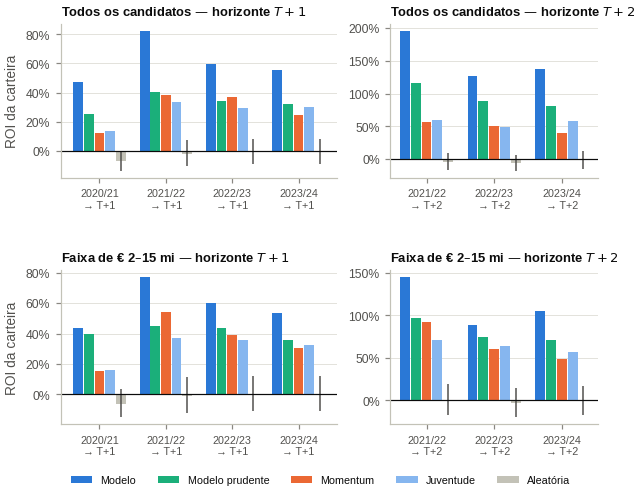

In [12]:
order = ["Modelo", "Modelo prudente", "Momentum", "Juventude", "Aleatória"]
colors = {"Modelo": pl.BLUE, "Modelo prudente": pl.AQUA, "Momentum": pl.ORANGE, "Juventude": "#86b6ef", "Aleatória": pl.NEUTRAL}
fig, axes = plt.subplots(2, 2, figsize=pl.figsize(12), gridspec_kw={"wspace": 0.22, "hspace": 0.6, "width_ratios": [4, 3]})
for (row, universe), (col, k) in [((r, u), (c, k)) for r, u in enumerate(UNIVERSES) for c, k in enumerate(HORIZONS)]:
    ax = axes[row, col]
    s = strat[(strat["horizonte"] == f"T+{k}") & (strat["universo"] == universe)]
    seasons = list(dict.fromkeys(s["temporada"]))
    width = 0.16
    for j, name in enumerate(order):
        v = s[s["estrategia"] == name].set_index("temporada").reindex(seasons)
        x = np.arange(len(seasons)) + (j - 2) * width
        ax.bar(x, v["roi_carteira_pct"], width=width * 0.92, color=colors[name], label=name)
        if name == "Aleatória":
            ax.vlines(x, v["roi_p05"], v["roi_p95"], color=pl.INK_SECONDARY, linewidth=1)
    ax.axhline(0, color=pl.INK, linewidth=0.8)
    ax.set_xticks(range(len(seasons)), [f"{t}\n→ T+{k}" for t in seasons], fontsize=7)
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_title(f"{universe} — horizonte $T+{k}$", fontsize=8.5)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("ROI da carteira")
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[n]) for n in order]
fig.legend(handles, order, loc="upper center", bbox_to_anchor=(0.5, 0.03), ncol=5, fontsize=7)
FIG.save(fig, "fig08_backtest_estrategias",
         "ROI realizado das carteiras de recrutamento por estratégia e temporada de decisão (backtest fora da amostra)",
         note="Carteiras com 10% dos candidatos de cada temporada e universo. ROI = ΣΔV / ΣV_T. "
              "Haste na estratégia aleatória: intervalo de 5% a 95% de 2.000 sorteios.")
plt.show()

**Leitura.** Em *backtest* fora da amostra, a estratégia do modelo supera todas as alternativas em
todas as temporadas, nos dois universos.

| Média das temporadas | Modelo | *Momentum* | Juventude | Aleatória |
|---|---|---|---|---|
| ROI da carteira, $T+1$, todos os candidatos | **61%** | 28% | 27% | −3% |
| ROI da carteira, $T+1$, faixa de € 2–15 mi | **59%** | 35% | 30% | −2% |
| ROI da carteira, $T+2$, todos os candidatos | **153%** | 49% | 56% | −4% |
| ROI da carteira, $T+2$, faixa de € 2–15 mi | **113%** | 67% | 64% | −1% |

Outros pontos do *backtest*:
- **Taxa de valorização:** 53–57% dos atletas da carteira do modelo se valorizam em $T+1$, e
  58–67% em $T+2$, contra 25% ao acaso.
- **Perdas graves (> 50%):** 3–4% em $T+1$, contra 5% do *momentum*.
- **Comparação com heurísticas:** o modelo dobra o ROI das heurísticas simples. Apostar em jovens
  ou em quem acabou de subir já rende acima do mercado, mas a combinação de idade, preço,
  trajetória e desempenho captura muito mais.
- **Modelo prudente** (seleção pelo cenário P10): menor ROI (33–41% em $T+1$), com a mesma taxa de
  perdas graves. Em carteiras diversificadas, a proteção pelo P10 não compensou.
- **ROI previsto da carteira:** subestima o realizado (53% previsto contra 61% realizado em $T+1$;
  103% contra 153% em $T+2$). É coerente com o encolhimento remanescente nos extremos documentado
  no notebook 04: o modelo é **conservador**.

### 7.1 Cenário de orçamento de um clube médio e risco financeiro

O cenário simula um clube com **€ 40 milhões** por janela, que contrata até **6 atletas** na faixa de
**€ 2–15 milhões**. É o mercado típico de um clube médio, que exclui as promessas da base (preço
residual) e os atletas caros. A estratégia do modelo compra em ordem decrescente de retorno
esperado. A referência sorteia a ordem de compra ao acaso (2.000 vezes), respeitando as mesmas
restrições. O risco é medido pela distribuição do ROI de carteira:
- **probabilidade de perda**;
- ***Value-at-Risk* (VaR) a 5%**, o ROI no pior quinto percentil;
- ***Conditional VaR* (CVaR)**, a média dos 5% piores casos.

A incerteza da carteira do modelo é estimada por *bootstrap* dos atletas selecionados.

,horizonte,temporada,atletas,investimento_mi,roi_modelo_pct,ganho_modelo_mi,roi_previsto_pct,p_perda_modelo,VaR5_modelo,CVaR5_modelo,roi_aleatorio_medio_pct,p_perda_aleatorio,VaR5_aleatorio,CVaR5_aleatorio,percentil_modelo_vs_aleatorio
0,T+1,2020/21,6,19.000,-2.630,-0.500,134.390,0.570,-23.810,-27.350,-6.090,0.670,-38.870,-44.100,64.100
1,T+1,2021/22,6,16.500,184.850,30.500,57.730,0.000,86.670,61.720,-0.850,0.610,-40.000,-45.330,99.650
2,T+1,2022/23,6,20.500,214.630,44.000,79.450,0.000,51.010,25.580,1.720,0.580,-38.170,-43.630,99.950
3,T+1,2023/24,6,17.000,77.060,13.100,113.400,0.160,-25.030,-37.290,0.360,0.590,-40.000,-45.300,96.250
4,T+2,2021/22,6,16.000,768.750,123.000,164.680,0.000,289.880,235.280,2.630,0.590,-58.110,-63.620,100.000
5,T+2,2022/23,6,27.500,394.550,108.500,137.750,0.000,181.950,136.010,-1.380,0.640,-57.340,-62.740,100.000
6,T+2,2023/24,6,16.500,250.300,41.300,296.610,0.000,25.620,14.480,-1.660,0.630,-56.560,-62.150,99.900


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig09_orcamento_risco.png


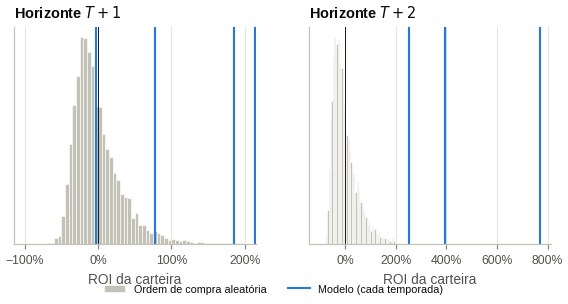

In [13]:
BUDGET, MAX_PRICE, MAX_PLAYERS = 40e6, PRICE_BAND[1], 6
risk_rows, dist_store = [], {}
for k in HORIZONS:
    for season, cands in UNIVERSES["Faixa de € 2–15 mi"](sim[sim["horizon"] == k]).groupby("season"):
        cands = cands.reset_index(drop=True)
        sel = it.budget_greedy(cands, "dv_pct_pred_mean", BUDGET, MAX_PRICE, MAX_PLAYERS)
        m = it.portfolio_metrics(sel)
        boot = np.array([it.portfolio_metrics(sel.sample(len(sel), replace=True, random_state=int(s)))["roi_carteira_pct"]
                         for s in rng.integers(0, 1e9, 1000)])
        rand = []
        for _ in range(N_DRAWS):
            shuffled = cands.assign(_r=rng.random(len(cands)))
            rand.append(it.portfolio_metrics(it.budget_greedy(shuffled, "_r", BUDGET, MAX_PRICE, MAX_PLAYERS))["roi_carteira_pct"])
        rand = np.array(rand)
        dist_store[(k, season)] = (m["roi_carteira_pct"], boot, rand)
        var_m, cvar_m = it.var_cvar(boot)
        var_r, cvar_r = it.var_cvar(rand)
        risk_rows.append({"horizonte": f"T+{k}", "temporada": sp.season_label(season), "atletas": int(m["n"]),
                          "investimento_mi": m["investimento_mi"], "roi_modelo_pct": m["roi_carteira_pct"],
                          "ganho_modelo_mi": m["ganho_liquido_mi"],
                          "roi_previsto_pct": (sel["value_T"] * sel["dv_pct_pred_mean"] / 100).sum() / sel["value_T"].sum() * 100,
                          "p_perda_modelo": float((boot < 0).mean()), "VaR5_modelo": var_m, "CVaR5_modelo": cvar_m,
                          "roi_aleatorio_medio_pct": rand.mean(), "p_perda_aleatorio": float((rand < 0).mean()),
                          "VaR5_aleatorio": var_r, "CVaR5_aleatorio": cvar_r,
                          "percentil_modelo_vs_aleatorio": float((rand < m["roi_carteira_pct"]).mean() * 100)})
risk = pd.DataFrame(risk_rows)
save_csv(risk, "tab08_orcamento_risco", index=False)
display(risk.round(2))

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), gridspec_kw={"wspace": 0.22})
for ax, k in zip(axes, HORIZONS):
    rand_all = np.concatenate([v[2] for (h, _), v in dist_store.items() if h == k])
    model_vals = [v[0] for (h, _), v in dist_store.items() if h == k]
    ax.hist(rand_all, bins=np.arange(-100, 205, 5), color=pl.NEUTRAL, edgecolor=pl.SURFACE, linewidth=0.4, density=True,
            label="Ordem de compra aleatória")
    for j, v in enumerate(model_vals):
        ax.axvline(v, color=pl.BLUE, linewidth=1.4, label="Modelo (cada temporada)" if j == 0 else None)
    ax.axvline(0, color=pl.INK, linewidth=0.6)
    ax.xaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_yticks([])
    ax.set_xlabel("ROI da carteira")
    ax.set_title(f"Horizonte $T+{k}$")
    ax.grid(axis="y", visible=False)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=7)
FIG.save(fig, "fig09_orcamento_risco",
         "Distribuição do ROI de carteiras com orçamento de € 40 milhões: modelo versus ordem de compra aleatória",
         note="Até 6 atletas com V_T entre € 2 e € 15 milhões. Histograma: 2.000 sorteios por temporada, temporadas agrupadas.")
plt.show()

**Leitura: risco de uma carteira concentrada.** No cenário de orçamento (até 6 atletas de € 2–15
mi, € 40 mi por janela), o modelo investe € 16–28 mi por temporada.

**$T+1$**

| Temporada de decisão | ROI | Percentil frente a 2.000 carteiras aleatórias |
|---|---|---|
| 2020/21 | −3% | 64 |
| 2021/22 | +185% | > 96 |
| 2022/23 | +215% | > 96 |
| 2023/24 | +77% | > 96 |

As carteiras aleatórias têm ROI médio próximo de zero, 57–67% de probabilidade de perda, VaR a 5%
de cerca de −38% e CVaR de cerca de −44%. Em $T+2$, o modelo fica acima do percentil 99,9 em todas
as temporadas.

A temporada 2020/21 é o caso de risco que deve ser discutido no artigo. A decisão foi tomada logo
após a revisão de valores da pandemia, e uma carteira de apenas seis atletas não diversifica o
choque. O *bootstrap* da carteira do modelo indica probabilidade de perda de 57% nesse ano, contra
0–16% nos demais.

*Implicação gerencial.* O modelo desloca toda a distribuição de retorno para a direita, mas não
elimina o risco de cauda de uma carteira concentrada. Com poucas contratações, a decisão deve
combinar a previsão com o intervalo de 80% e com diversificação por posição e faixa etária.

## 8. Mapa de oportunidades e lista de observação (teste 2023/24)

O mapa de oportunidades é o artefato gerencial do estudo: cada atleta posicionado pelo **retorno
esperado** (eixo x) e pelo **cenário pessimista** (P10, eixo y). O quadrante superior direito
reúne os atletas com alto potencial e risco limitado. A lista mostra as 15 maiores oportunidades
na faixa de € 2–15 milhões, como o modelo as apontaria em 30/06/2024, e o que aconteceu até
30/06/2025.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig10_mapa_oportunidades.png


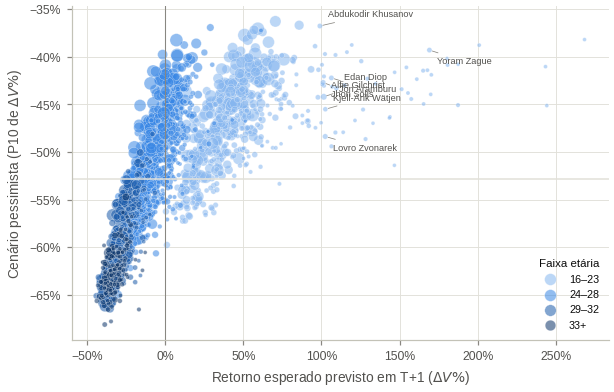

Lista de observação: 53% se valorizaram; ROI 132.2%; 73% dentro do intervalo de 80%


,fb_player,fb_team,league,faixa,position_group,valor_T_mi,previsto_mediana,previsto_esperanca,cenario_p10,cenario_p90,realizado,valor_T1_mi
7468,Yoram Zague,Paris SG,FRA-Ligue 1,16–23,DEF,2.500,95.900,169.100,-39.300,445.300,0.000,2.500
7650,Edan Diop,Monaco,FRA-Ligue 1,16–23,MEI,2.000,52.600,109.600,-43.300,376.000,-70.000,0.600
7332,Jon Aramburu,Real Sociedad,ESP-La Liga,16–23,DEF,2.500,50.300,106.400,-42.200,324.100,500.000,15.000
7722,Kjell-Arik Wätjen,Dortmund,GER-Bundesliga,16–23,MEI,2.000,47.500,102.500,-45.500,275.400,25.000,2.500
7651,Lovro Zvonarek,Bayern Munich,GER-Bundesliga,16–23,MEI,3.000,47.400,102.400,-48.400,209.400,-50.000,1.500
7608,Alfie Gilchrist,Chelsea,ENG-Premier League,16–23,DEF,5.000,46.700,101.500,-44.200,264.400,60.000,8.000
7454,Jhon Solis,Girona,ESP-La Liga,16–23,MEI,3.000,46.400,101.100,-42.700,263.800,-16.700,2.500
7148,Abdukodir Khusanov,Lens,FRA-Ligue 1,16–23,DEF,2.500,44.900,99.000,-36.700,225.300,"1,300.000",35.000
7561,Adu Ares,Athletic Club,ESP-La Liga,16–23,ATA,2.000,44.200,98.100,-41.300,276.800,-20.000,1.600
7589,Lewis Dobbin,Everton,ENG-Premier League,16–23,ATA,2.500,44.000,97.800,-44.200,340.300,0.000,2.500


In [14]:
k = 1
h = sim[(sim["horizon"] == k) & sim["is_holdout"]].copy()
h["p10_pct"] = np.expm1(h["q10_conf"]) * 100
h["p90_pct"] = np.expm1(h["q90_conf"]) * 100
fig, ax = plt.subplots(figsize=pl.figsize(10))
for band, color in zip(BANDS, pl.AGE_BAND_COLORS):
    m = h[band_col] == band
    ax.scatter(h.loc[m, "dv_pct_pred_mean"], h.loc[m, "p10_pct"], s=6 + h.loc[m, "value_T"] / 1e6 * 2.2, color=color, alpha=0.55,
               linewidths=0.3, edgecolors=pl.SURFACE, label=band)
watch = h[h["value_T"].between(*PRICE_BAND)].nlargest(15, "dv_pct_pred_mean")
for j, (_, r) in enumerate(watch.head(8).iterrows()):
    ax.annotate(r["fb_player"], (r["dv_pct_pred_mean"], r["p10_pct"]), xytext=(5, 6 if j % 2 else -9),
                textcoords="offset points", fontsize=6, color=pl.INK_SECONDARY,
                arrowprops={"arrowstyle": "-", "color": pl.INK_MUTED, "linewidth": 0.5})
ax.axvline(0, color=pl.INK_MUTED, linewidth=0.7)
ax.axhline(h["p10_pct"].median(), color=pl.GRID, linewidth=1)
ax.xaxis.set_major_formatter(pl.pct_formatter(0))
ax.yaxis.set_major_formatter(pl.pct_formatter(0))
ax.set_xlabel("Retorno esperado previsto em T+1 ($\\Delta V\\%$)")
ax.set_ylabel("Cenário pessimista (P10 de $\\Delta V\\%$)")
ax.legend(title="Faixa etária", fontsize=7, title_fontsize=7.5, loc="lower right", markerscale=1.2)
FIG.save(fig, "fig10_mapa_oportunidades",
         "Mapa de oportunidades de recrutamento em 30/06/2024: retorno esperado versus cenário pessimista em T+1",
         note="Tamanho do ponto proporcional a V_T. Rótulos: oito maiores retornos esperados na faixa de € 2–15 milhões. Previsões fora da amostra.")
plt.show()

watch_tab = watch.assign(
    valor_T_mi=watch["value_T"] / 1e6, previsto_mediana=watch["dv_pct_pred_median"], previsto_esperanca=watch["dv_pct_pred_mean"],
    cenario_p10=watch["p10_pct"], cenario_p90=watch["p90_pct"], realizado=watch["dv_pct_true"],
    valor_T1_mi=(watch["value_T"] + watch["dv_true"]) / 1e6,
)[["fb_player", "fb_team", "league", band_col, "position_group", "valor_T_mi", "previsto_mediana", "previsto_esperanca",
   "cenario_p10", "cenario_p90", "realizado", "valor_T1_mi"]].rename(columns={band_col: "faixa"})
save_csv(watch_tab, "tab09_lista_observacao_2324", index=False)
inside = ((watch_tab["realizado"] >= watch_tab["cenario_p10"]) & (watch_tab["realizado"] <= watch_tab["cenario_p90"])).mean()
print(f"Lista de observação: {(watch_tab['realizado'] > 0).mean() * 100:.0f}% se valorizaram; "
      f"ROI {watch['dv_true'].sum() / watch['value_T'].sum() * 100:.1f}%; {inside * 100:.0f}% dentro do intervalo de 80%")
watch_tab.round(1)

**Leitura.** Na lista de observação, com as 15 maiores oportunidades de € 2–15 mi apontadas em
30/06/2024, 53% se valorizaram até 30/06/2025, e o ROI da lista foi de 132%. Os destaques são
**Abdukodir Khusanov** (Lens, € 2,5 mi → € 35 mi), **Jon Aramburu** (€ 2,5 mi → € 15 mi),
**Senny Mayulu** (€ 5 mi → € 15 mi) e **Conor Bradley** (€ 15 mi → € 30 mi). Houve também perdas
relevantes, como Edan Diop (−70%) e Lovro Zvonarek (−50%). Isso reforça a leitura de carteira: o
retorno vem de poucos acertos grandes, e os erros são limitados (P10 em torno de −40%).

O mapa de oportunidades (Figura 10) traduz a decisão em dois eixos: retorno esperado e cenário
pessimista. Os jovens (16–23 anos) ocupam a região de maior retorno esperado com risco semelhante
ao dos atletas de 24–28 anos. Os veteranos concentram-se no quadrante de baixo retorno e alto
risco.

## 9. Índice de figuras

In [15]:
FIG.write_index()[["figura", "arquivo", "legenda"]]

,figura,arquivo,legenda
0,1,fig01_shap_beeswarm_T1.png,Valores SHAP das 20 variáveis mais importantes...
1,2,fig02_shap_beeswarm_T2.png,Valores SHAP das 20 variáveis mais importantes...
2,3,fig03_grupos_por_categoria.png,Participação de cada grupo de variáveis na exp...
3,4,fig04_top5_por_categoria.png,As cinco variáveis com maior contribuição médi...
4,5,fig05_desempenho_por_posicao.png,As dez métricas tático-técnicas com maior cont...
5,6,fig06_dependencia_shap.png,Gráficos de dependência SHAP das principais va...
6,7,fig07_waterfall_exemplos.png,Decomposição SHAP da previsão de valorização e...
7,8,fig08_backtest_estrategias.png,ROI realizado das carteiras de recrutamento po...
8,9,fig09_orcamento_risco.png,Distribuição do ROI de carteiras com orçamento...
9,10,fig10_mapa_oportunidades.png,Mapa de oportunidades de recrutamento em 30/06...


## 10. Síntese para o artigo (Resultados e Discussão)

**1. O que determina a valorização futura (SHAP)**
- **Idade:** 27–35% da explicação, com efeito linear decrescente.
- **Nível de preço:** 11–14% da explicação; atletas mais caros se valorizam menos.
- **Trajetória do valor:** 20–24%, em especial o **gap de avaliação** e a variação recente.
- **Desempenho tático-técnico:** 24–32%. Lideram a participação nos minutos e a nota, e, entre os
  atacantes, o xG e a finalização.

**2. Variação ao longo da carreira**
- O desempenho pesa mais no **auge** (35–41% em 24–28 anos).
- Nos **veteranos**, a idade domina (≈ 40%).
- Isso contraria a premissa de que o rendimento operacional governaria o valor dos atletas mais
  velhos.

**3. Decisão *buy-low / sell-high***
- Em *backtest* fora da amostra (2020/21–2023/24), carteiras selecionadas pelo modelo rendem ROI
  médio de **59–61% em $T+1$** e **113–153% em $T+2$**.
- As referências ficam bem abaixo: −3% a −1% ao acaso, 27–35% com a heurística de juventude e
  28–67% com o *momentum*.
- A estratégia supera as alternativas em todas as temporadas.

**4. Risco**
- Carteiras concentradas continuam expostas a choques de mercado. Em 2020/21, logo após a
  revisão da pandemia, o ROI foi de −3%, com probabilidade de perda de 57%.
- O intervalo de 80% e a diversificação são parte da recomendação gerencial.

**Limitações para a discussão**
- O SHAP descreve o **modelo**, e não relações causais.
- Os efeitos de variáveis colineares se dividem entre si.
- O $V_T$ do Transfermarkt é usado como preço de compra e de venda, sem custos de transação,
  salários nem a diferença entre valor de mercado e preço efetivo. O ROI simulado é, portanto, de
  **valor de mercado**, e não de caixa.
- As carteiras são retrospectivas (2020–2024). A lista de 2023/24 é apresentada como ilustração.